# **Analisis Ulasan Produk Skincare**

Dokumen ini menguraikan rencana untuk menganalisis ribuan ulasan produk perawatan kulit (skincare) untuk mendapatkan wawasan bisnis yang dapat ditindaklanjuti.

## **1. Latar Belakang & Tujuan Proyek**
**Masalah:** Sebuah toko atau merek dengan banyak produk kesulitan untuk memantau performa masing-masing produk secara efisien. Mana produk yang menjadi favorit pelanggan? Mana yang mengecewakan? Apa tema keluhan atau pujian yang berulang? Jawaban atas pertanyaan ini terkubur dalam ribuan ulasan tidak terstruktur.

**Tujuan:**
- Melakukan **klasifikasi sentimen** ('Positif', 'Negatif', 'Netral') pada semua ulasan berdasarkan kolom Rating yang ada.
- Mengidentifikasi produk dengan **performa terbaik** (rating rata-rata tertinggi) dan **terburuk** (rating rata-rata terendah).
- Menggunakan **IBM Granite** untuk **merangkum (summarization)** alasan utama di balik sentimen positif pada 3 produk teratas dan sentimen negatif pada 3 produk terbawah.
- Memberikan **rekomendasi strategis** terkait manajemen produk dan pemasaran berdasarkan analisis data.

## **2. Proses Analisis**
1. **Pengolahan Data:** Dataset dibersihkan dengan menghapus baris yang tidak memiliki data Review atau Rating.
2. **Klasifikasi Sentimen Berbasis Aturan:** Menerapkan logika sederhana untuk membuat kolom baru Sentiment. Ulasan dengan Rating 4 atau 5 diklasifikasikan sebagai 'Positif', Rating 3 sebagai 'Netral', dan Rating 1 atau 2 sebagai 'Negatif'.
3. **Analisis Statistik & Visualisasi:**
 - Membuat *bar chart* untuk menampilkan distribusi keseluruhan sentimen (Positif, Negatif, Netral) di seluruh produk.
 - Membuat **tabel ringkasan** yang menunjukkan setiap produk, jumlah ulasan, rating rata-rata, dan distribusi persentase sentimennya.
 - Membuat visualisasi *bar chart* terpisah untuk menampilkan **10 produk teratas** dan **10 produk terbawah** berdasarkan rating rata-rata.
4. **Summarization Tema dengan AI:**
 - **Analisis Produk Teratas & Terbawah:** Untuk 3 produk dengan rating tertinggi dan 3 produk dengan rating terendah, ulasan mereka dikelompokkan. Model AI IBM Granite kemudian digunakan untuk merangkum tema pujian (untuk produk teratas) dan keluhan (untuk produk terbawah) yang paling umum.

## **3. Insight & Temuan yang Potensial**
- "Produk X, Y, dan Z secara konsisten menerima rating terendah. AI menyimpulkan keluhan utama pada ketiganya adalah 'tekstur lengket dan berat', menunjukkan potensi masalah pada basis formulasi yang sama."
- "Meskipun ada banyak produk dalam dataset, sebagian besar sentimen positif berasal dari beberapa produk 'pahlawan' (hero products), yang semuanya dipuji karena 'efek mencerahkan'."
- "Keluhan yang dirangkum AI untuk produk A adalah 'menyebabkan bruntusan pada kulit berminyak'. Ini menandakan adanya ketidakcocokan produk dengan segmen pelanggan tertentu."
- "Produk dengan rating bintang 3 (Netral) seringkali bukan karena kualitasnya buruk, melainkan karena ekspektasi yang salah. AI dapat menemukan tema ulasan seperti 'bagus, tapi tidak seefektif yang diiklankan'."

## **4. Rekomendasi & Kesimpulan**
- **Untuk Manajemen Produk & Inventaris:** Merekomendasikan untuk meninjau ulang formulasi atau bahkan menghentikan penjualan produk dengan performa terburuk untuk menghindari kekecewaan pelanggan lebih lanjut.
- **Untuk Pemasaran:** Menyarankan untuk membuat kampanye "Koleksi Favorit Pelanggan" yang berfokus pada produk-produk dengan rating tertinggi. Gunakan rangkuman pujian dari AI sebagai materi promosi.
- **Untuk Pengembangan Produk Baru:** Menyarankan pengembangan produk yang secara spesifik menjawab keluhan paling umum yang ditemukan pada produk-produk berperforma buruk.

## **Langkah 1: Instalasi Library**
Langkah pertama adalah menginstal library yang diperlukan untuk berinteraksi dengan model AI melalui Replicate dan LangChain.

In [ ]:
# Menginstal library langchain_community untuk berinteraksi dengan berbagai model bahasa
# Menginstal library replicate untuk mengakses model yang di-hosting di platform Replicate
%%capture
!pip install langchain_community replicate

## **Langkah 2: Impor Library dan Memuat Data**
Selanjutnya, kita mengimpor semua library yang dibutuhkan untuk analisis data, visualisasi, dan memuat dataset dari Kaggle.

In [ ]:
# Mengimpor library pandas untuk manipulasi dan analisis data (DataFrame)
import pandas as pd
# Mengimpor matplotlib.pyplot untuk membuat visualisasi data statis
import matplotlib.pyplot as plt
# Mengimpor seaborn untuk membuat visualisasi data statistik yang lebih menarik
import seaborn as sns
# Mengimpor WordCloud untuk membuat visualisasi kata dari teks
from wordcloud import WordCloud
# Mengimpor warnings untuk mengabaikan pesan peringatan yang tidak kritikal
import warnings
# Mengimpor kagglehub untuk mengunduh dataset langsung dari Kaggle
import kagglehub

# Mengatur agar pesan peringatan diabaikan untuk menjaga output tetap bersih
warnings.filterwarnings('ignore')
# Mengatur opsi pandas agar semua kolom ditampilkan saat mencetak DataFrame
pd.set_option('display.max_columns', None)
# Mengatur lebar tampilan output pandas
pd.set_option('display.width', 1000)

print("📚 Mengimpor library...")

try:
    # Mengunduh dataset skincare review dari Kaggle Hub
    path = kagglehub.dataset_download("hafidahmusthaanah/skincare-review")
    # Membaca file CSV ke dalam DataFrame pandas
    df = pd.read_csv(path + '/00. Review.csv')
    print(f"✔️ Dataset berhasil dimuat. Jumlah data: {len(df)} baris.")
    print("\nContoh Data:")
    # Menampilkan 5 baris pertama dari dataset
    print(df.head())
except FileNotFoundError:
    print(f"❌ ERROR: File tidak ditemukan. Pastikan path file sudah benar.")

📚 Mengimpor library...
✔️ Dataset berhasil dimuat. Jumlah data: 8646 baris.

Contoh Data:
          Product      UserName          SkinCond_Age                                     Recommend     PostDate                                             Review  Rating
0  Perfect 3D Gel         <user>               35 - 39                <user> recommends this product!  12 Jul 2020  Di aku beneran kerja. Melembabkan bgt. Tp gak ...       5
1  Perfect 3D Gel  <user>       Normal, 19 - 24  <user> doesn't recommend this product!  31 May 2020  ga cocok bgttt bikin muka bruntusan dan lgsg m...       2
2  Perfect 3D Gel      <user>  Combination, 19 - 24      <user> doesn't recommend this product!  30 Jul 2020  [SOLD]baru pertama kali nyoba dan beli karna l...       2
3  Perfect 3D Gel   <user>          Dry, 30 - 34   <user> doesn't recommend this product!  12 Jul 2020  enak sih di mukaku, yg tadinya kering jd lemba...       3
4  Perfect 3D Gel     <user>         Oily, 19 - 24            <user> recom

## **Langkah 3: Pra-pemrosesan Data dan Klasifikasi Sentimen**
Data mentah perlu dibersihkan dan disiapkan. Di sini, kita akan membuang baris yang tidak memiliki ulasan atau rating, lalu membuat kolom 'Sentiment' berdasarkan nilai 'Rating'.

In [ ]:
print("\n⚙️ Memulai pra-pemrosesan data...")

# Menghapus baris yang memiliki nilai kosong di kolom 'Review' atau 'Rating'
df.dropna(subset=['Review', 'Rating'], inplace=True)
# Mengubah tipe data kolom 'Rating' menjadi integer
df['Rating'] = df['Rating'].astype(int)

# Fungsi untuk mengklasifikasikan sentimen berdasarkan rating
def klasifikasi_berdasarkan_rating(rating):
    if rating >= 4:
        return 'Positif'  # Rating 4-5 dianggap positif
    elif rating == 3:
        return 'Netral'   # Rating 3 dianggap netral
    else:
        return 'Negatif'  # Rating 1-2 dianggap negatif

# Menerapkan fungsi klasifikasi untuk membuat kolom 'Sentiment' baru
df['Sentiment'] = df['Rating'].apply(klasifikasi_berdasarkan_rating)

print("✔️ Kolom 'Sentiment' berhasil dibuat berdasarkan 'Rating'.")
print("\nContoh data dengan kolom sentimen:")
# Menampilkan contoh hasil klasifikasi sentimen
print(df[['Product', 'Rating', 'Sentiment']].head())


⚙️ Memulai pra-pemrosesan data...
✔️ Kolom 'Sentiment' berhasil dibuat berdasarkan 'Rating'.

Contoh data dengan kolom sentimen:
          Product  Rating Sentiment
0  Perfect 3D Gel       5   Positif
1  Perfect 3D Gel       2   Negatif
2  Perfect 3D Gel       2   Negatif
3  Perfect 3D Gel       3    Netral
4  Perfect 3D Gel       3    Netral


## **Langkah 4: Analisis dan Visualisasi Data**
Pada tahap ini, kita menganalisis distribusi sentimen dan performa produk, lalu memvisualisasikannya untuk memudahkan interpretasi.


📊 Memulai analisis dan visualisasi data...


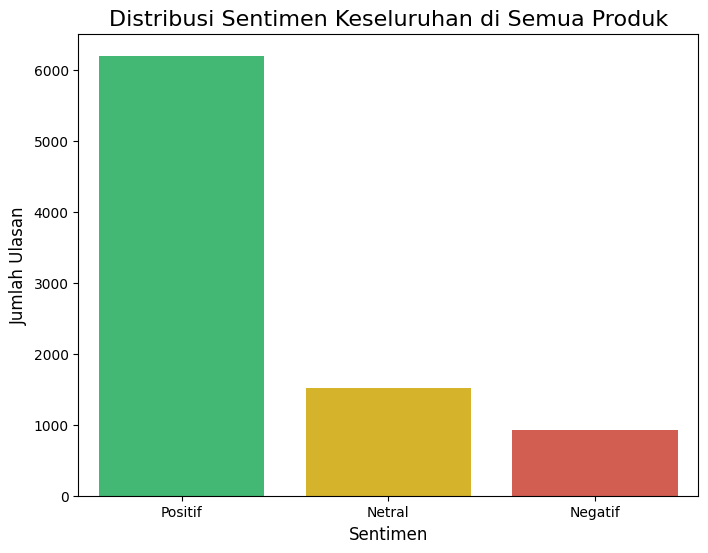


--- Tabel Ringkasan Performa Produk ---
                                         Product  Jumlah_Ulasan  Rating_Rata_Rata  Persen_Negatif  Persen_Netral  Persen_Positif
6                              A-Lash Wink Serum              1          5.000000            0.00           0.00           100.0
680      Teatree Care Solution Essential Mask EX             10          5.000000            0.00           0.00           100.0
268  Game Changer Tripeptide Eye Concentrate Gel              7          5.000000            0.00           0.00           100.0
248                        Facial Treatment Mask             10          5.000000            0.00           0.00           100.0
209                   Extra Beauty Eyelash Tonic              3          5.000000            0.00           0.00           100.0
..                                           ...            ...               ...             ...            ...             ...
560            Raspberry Roots Depuffing Eye Gel        

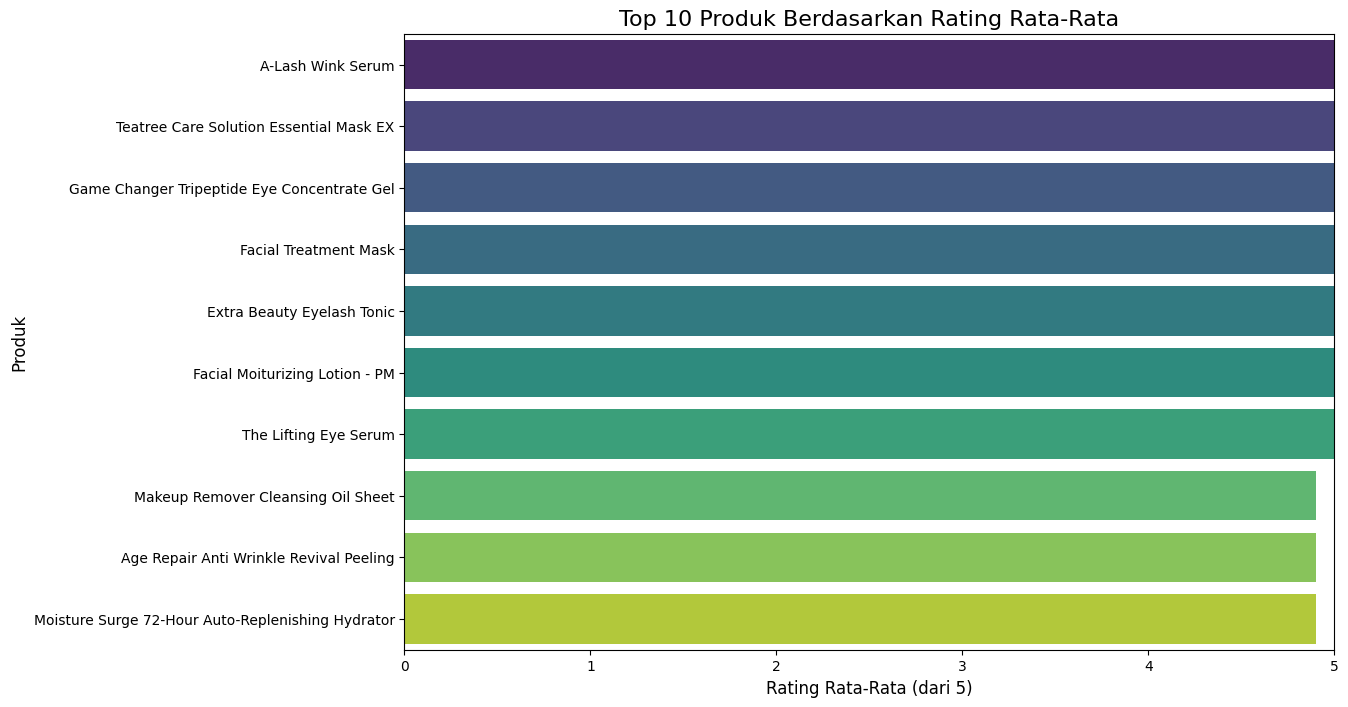

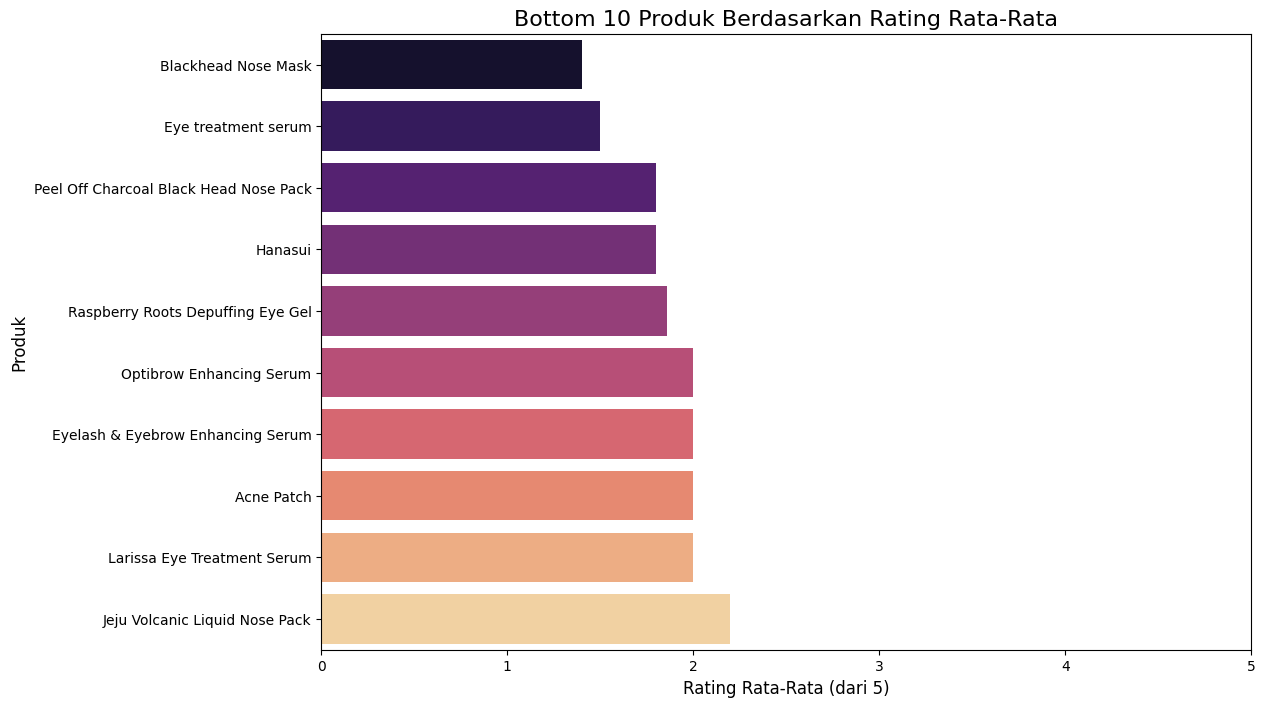

In [ ]:
print("\n📊 Memulai analisis dan visualisasi data...")

# Membuat plot untuk distribusi sentimen keseluruhan
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Sentiment', order=['Positif', 'Netral', 'Negatif'], palette={'Positif':'#2ecc71', 'Netral':'#f1c40f', 'Negatif':'#e74c3c'})
plt.title('Distribusi Sentimen Keseluruhan di Semua Produk', fontsize=16)
plt.xlabel('Sentimen', fontsize=12)
plt.ylabel('Jumlah Ulasan', fontsize=12)
plt.show()

# Mengelompokkan data berdasarkan produk untuk menghitung jumlah ulasan dan rating rata-rata
product_performance = df.groupby('Product').agg(
    Jumlah_Ulasan=('Product', 'count'),
    Rating_Rata_Rata=('Rating', 'mean')
).reset_index()

# Menghitung distribusi sentimen (jumlah) untuk setiap produk
sentiment_dist = df.groupby(['Product', 'Sentiment']).size().unstack(fill_value=0)
# Menghitung distribusi sentimen (persentase) untuk setiap produk
sentiment_dist_percent = sentiment_dist.apply(lambda x: x / x.sum() * 100, axis=1).round(2)
sentiment_dist_percent.columns = [f'Persen_{col}' for col in sentiment_dist_percent.columns]

# Menggabungkan data performa dan distribusi sentimen ke dalam satu tabel ringkasan
summary_table = pd.merge(product_performance, sentiment_dist_percent, on='Product', how='left').fillna(0)
# Mengurutkan tabel berdasarkan rating rata-rata dari tertinggi ke terendah
summary_table = summary_table.sort_values(by='Rating_Rata_Rata', ascending=False)

print("\n--- Tabel Ringkasan Performa Produk ---")
print(summary_table)

# Mengambil 10 produk teratas dan 10 produk terbawah
top_10_produk = summary_table.head(10)
bottom_10_produk = summary_table.sort_values(by='Rating_Rata_Rata', ascending=True).head(10)

# Visualisasi 10 produk terbaik
plt.figure(figsize=(12, 8))
sns.barplot(data=top_10_produk, x='Rating_Rata_Rata', y='Product', palette='viridis')
plt.title('Top 10 Produk Berdasarkan Rating Rata-Rata', fontsize=16)
plt.xlabel('Rating Rata-Rata (dari 5)', fontsize=12)
plt.ylabel('Produk', fontsize=12)
plt.xlim(0, 5)
plt.show()

# Visualisasi 10 produk terburuk
plt.figure(figsize=(12, 8))
sns.barplot(data=bottom_10_produk, x='Rating_Rata_Rata', y='Product', palette='magma')
plt.title('Bottom 10 Produk Berdasarkan Rating Rata-Rata', fontsize=16)
plt.xlabel('Rating Rata-Rata (dari 5)', fontsize=12)
plt.ylabel('Produk', fontsize=12)
plt.xlim(0, 5)
plt.show()

## **Langkah 5: Inisialisasi Model AI**
Langkah ini menyiapkan koneksi ke model AI (IBM Granite) menggunakan API dari Replicate. Kunci API diambil dengan aman dari environment Colab.

In [ ]:
# Mengimpor kelas Replicate dari langchain_community untuk menginisialisasi model
from langchain_community.llms import Replicate
import os
from google.colab import userdata

# Mengambil API token dari 'secrets' di Google Colab untuk keamanan
api_token = userdata.get('api_token')
# Mengatur token sebagai variabel lingkungan yang diperlukan oleh Replicate
os.environ["REPLICATE_API_TOKEN"] = api_token

# Menentukan model yang akan digunakan (IBM Granite 8B Instruct)
model = "ibm-granite/granite-3.3-8b-instruct"
# Menginisialisasi model Replicate dengan token API
output = Replicate(
  model=model,
  replicate_api_token=api_token,
)

## **Langkah 6: Peringkasan Ulasan dengan AI**
Fungsi ini menggunakan AI untuk merangkum alasan utama di balik sentimen positif dan negatif untuk produk-produk yang dipilih.

Note: Lakukan percobaan prompt beberapa kali untuk mendapatkan hasil review yang maksimal

In [ ]:
print("\n🧠 Memulai proses peringkasan dengan AI...")

def rangkum_alasan(daftar_review, jenis_sentimen):
    """Fungsi untuk merangkum alasan dari daftar ulasan menggunakan AI."""
    # Jika jumlah ulasan terlalu banyak, ambil sampel acak 30 ulasan untuk efisiensi
    if len(daftar_review) > 30:
        daftar_review = pd.Series(daftar_review).sample(30).tolist()

    # Menggabungkan daftar ulasan menjadi satu teks besar
    teks_gabungan = "\n- ".join(daftar_review)

    # Membuat prompt yang detail untuk mengarahkan AI agar memberikan output yang diinginkan
    prompt = f"""
    Anda adalah seorang analis riset pasar yang ahli dalam menyarikan inti dari ulasan pelanggan.
    Berdasarkan kumpulan ulasan produk dengan sentimen "{jenis_sentimen}" berikut, identifikasi dan rangkum 3 alasan utama yang paling sering muncul.

    TUGAS ANDA:
    Berikan jawaban HANYA dalam format daftar bernomor. Setiap poin harus berupa frasa yang sangat ringkas dan langsung ke intinya, sama seperti contoh di bawah.

    PERATURAN PENTING:
    - JANGAN menyertakan penjelasan tambahan.
    - JANGAN menyertakan kalimat pembuka atau penutup.
    - JANGAN mengutip bagian dari ulasan.
    - JANGAN ulangi judul atau instruksi apa pun.

    Contoh Jawaban Sempurna:
    1. Efek melembapkan yang tahan lama.
    2. Tekstur ringan dan cepat meresap.
    3. Aroma menenangkan dan tidak menyengat.

    Berikut adalah ulasannya:
    - {teks_gabungan}

    Ringkasan 3 Alasan Utama:
    """
    try:
        # Memanggil model AI dengan prompt yang telah dibuat
        response = output.invoke(prompt)
        # Mengembalikan hasil ringkasan setelah membersihkan spasi yang tidak perlu
        return response.strip()
    except Exception as e:
        return f"Error saat meringkas: {e}"

# Menganalisis 3 produk teratas
top_3_produk = summary_table.head(3)['Product'].tolist()
print("\n--- Analisis Produk Terbaik (Sentimen Positif) ---")
for produk in top_3_produk:
    print(f"\n✨ Meringkas pujian untuk produk: '{produk}'")
    ulasan_positif = df[(df['Product'] == produk) & (df['Sentiment'] == 'Positif')]['Review'].tolist()
    if ulasan_positif:
        ringkasan_pujian = rangkum_alasan(ulasan_positif, "POSITIF")
        print(ringkasan_pujian)
    else:
        print("Tidak ada ulasan positif yang cukup untuk dirangkum.")

# Menganalisis 3 produk terburuk
bottom_3_produk = summary_table.sort_values(by='Rating_Rata_Rata', ascending=True).head(3)['Product'].tolist()
print("\n\n--- Analisis Produk Terburuk (Sentimen Negatif) ---")
for produk in bottom_3_produk:
    print(f"\n⚠️ Meringkas keluhan untuk produk: '{produk}'")
    ulasan_negatif = df[(df['Product'] == produk) & (df['Sentiment'] == 'Negatif')]['Review'].tolist()
    if ulasan_negatif:
        ringkasan_keluhan = rangkum_alasan(ulasan_negatif, "NEGATIF")
        print(ringkasan_keluhan)
    else:
        print("Tidak ada ulasan negatif yang cukup untuk dirangkum.")


🧠 Memulai proses peringkasan dengan AI...

--- Analisis Produk Terbaik (Sentimen Positif) ---

✨ Meringkas pujian untuk produk: 'A-Lash Wink Serum'
1. Hasil visible bulu mata panjang & lentik
2. Perubahan signifikan di bulu mata bawah
3. Design aplikator ringan dan mudah digunakan

✨ Meringkas pujian untuk produk: 'Teatree Care Solution Essential Mask EX'
1. Efektif menurunkan jerawat dan iritasi wajah.
2. Essence yang banyak dan cepat meresap ke kulit.
3. Bau tea tree yang membantu mengurangi bau dan meredakan kulit.

✨ Meringkas pujian untuk produk: 'Game Changer Tripeptide Eye Concentrate Gel'
1. Effektif dalam menghilangkan lingkar hitam di sekitar mata
2. Aplikator keramik yang higienis dan praktis
3. Tampilan kualitas tinggi dan hasil yang visible dalam waktu singkat


--- Analisis Produk Terburuk (Sentimen Negatif) ---

⚠️ Meringkas keluhan untuk produk: 'Blackhead Nose Mask'
1. Ini ineffective in extracting blackheads.
2. Product does not remove or reduce blackheads as claimed